In [1]:
import tensorflow as tf
from tensorflow.keras.preprocessing import image_dataset_from_directory
import numpy as np
import os
import random
import shutil # shell utility
from PIL import Image
from google.colab import drive
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
drive.mount('/content/drive') # mount Google Drive

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
def show_images(directory, prefix, ids):
  '''
  Show corrupted images in each directory
  Arg:
    directory: The path to the directory containing the images.
    prefix: The prefix of the image files.
    ids: The list of corrupted image ids.
  '''
  n_fig = len(ids)
  # optimize the subplots to be as square as possible
  n_row = int(np.ceil(np.sqrt(n_fig)))
  n_col = int(np.ceil(n_fig/n_row))
  fig, axes = plt.subplots(n_row,n_col,figsize=(n_col*5,n_row*5))
  for i in range(n_fig):
    img = Image.open(os.path.join(directory,prefix+str(ids[i])+'.jpg'))
    plt.subplot(n_row,n_col,i+1)
    plt.imshow(img)
    plt.axis('off')
  plt.show()

def rename_files(directory,prefix,old_prefix=''):
  '''
  Renames files in the directory with the prefix
  Arg:
    directory: The path to the directory containing the files.
    prefix: The new prefix to use.
    old_prefix: Optional, the old prefix to replace.
  '''
  for filename in os.listdir(directory):
    filepath = os.path.join(directory,filename)
    if not os.path.isfile(filepath):
      continue  # Skip if not a file
    if not filename.startswith(prefix):
      if old_prefix and filename.startswith(old_prefix):
        new_name = filename.replace(old_prefix, prefix, 1)
      else:
        new_name = prefix + filename
      old_path = os.path.join(directory, filename)
      new_path = os.path.join(directory, new_name)
      os.rename(old_path, new_path)
      print(f"Renamed '{filename}' to '{new_name}'")
    else:
      print(f"Skipped '{filename}' (already start with '{prefix}')")

def trash_files(directory,prefix,ids):
  '''
  Moves files match ids into trash folder.
  Arg:
    directory: The path to the directory containing the files.
    prefix: The prefix of the files to move.
    ids: The list of ids to move.
  '''
  trash_dir = os.path.join(directory,'..','trash')
  if not os.path.exists(trash_dir):
    os.makedirs(trash_dir)
  for id in ids:
    filename = os.path.join(directory,prefix+str(id)+'.jpg')
    if os.path.exists(filename):
      shutil.move(filename,trash_dir)
      print(f"Moved {filename} to {trash_dir}")
    else:
      print(f"File {filename} does not exist.")

def split_dataset(directory,train_ratio=0.8, val_ratio=0.1, test_ratio=0.1, seed=41):
  '''
  Splits the dataset into train, validation, and test sets based on the given ratios.
  Arg:
    directory: The path to the directory containing the dataset.
    train_ratio: The ratio of the dataset to use for training.
    val_ratio: The ratio of the dataset to use for validation.
    test_ratio: The ratio of the dataset to use for testing.
    seed: The seed to use for the random number generator.
  '''
  random.seed(seed)

  classes = os.listdir(directory)
  for class_name in classes:
    if class_name == 'trash' or class_name == 'train' or class_name == 'validation' or class_name == 'test':
      continue
    class_dir = os.path.join(directory,class_name)
    if not os.path.isdir(class_dir):
      continue
    images = os.listdir(class_dir)
    random.shuffle(images)
    n_total = len(images)
    n_train = int(n_total * train_ratio)
    n_val = int(n_total * val_ratio)
    data_splits = {'train': images[:n_train],
                   'validation': images[n_train:n_train+n_val],
                   'test': images[n_train+n_val:]}
    for split_name, split_images in data_splits.items():
      split_class_dir = os.path.join(directory,split_name,class_name)
      if not os.path.exists(split_class_dir):
        os.makedirs(split_class_dir)
      for image in split_images:
        source = os.path.join(class_dir,image)
        target = os.path.join(split_class_dir,image)
        shutil.copy2(source,target)
    print(f"Processed {class_name}: {n_total} files split into train/val/test")

def image_check(directory):
  '''
  Removes corrupted images.
  '''
  for root, _, files in os.walk(directory):
    for file in files:
      try:
        img = Image.open(os.path.join(root,file))
        img.verify()
        img = Image.open(os.path.join(root,file))
        if img.mode not in ['RGB', 'L', 'RGBA']:
          print(f"Invalid image mode: {os.path.join(root,file)} \n")
          img = img.convert('RGB')
        elif img.mode == 'L':
          img = img.convert('RGB')
        elif img.mode == 'RGBA':
          img = img.convert('RGB')
        img.save(os.path.join(root,file))
      except Exception as e:
        print(f"Corrupted image: {os.path.join(root,file)}, {e}\n")
        os.remove(os.path.join(root,file))

def count_images(directory):
  '''
  Counts the number of images in the directory.
  '''
  count = os.listdir(directory)
  return len(count)

def plot_data_distribution(data_distribution):
  '''
  Plots the data distribution.
  Arg:
    data_distribution: A dictionary containing the data distribution.
  '''
  classes = data_distribution.keys()
  counts = data_distribution.values()
  plt.bar(classes,counts)
  plt.xlabel('Class')
  plt.ylabel('Count')
  plt.title('Data Distribution')
  plt.show()

def force_rgb(image,label):
  '''
  Covert corrupted image to RBG
  '''
  if image.shape[-1] == 2:
    image = tf.math.reduce_mean(image,axis=-1,keepdims=True)
    image = tf.image.grayscale_to_rgb(image)
  return image,label

def image_resolution(directory):
  '''
  return the resolutions of the image in the directory
  '''
  resolutions = []
  for root ,_,files in os.walk(directory):
    for file in files:
      if file.lower().endswith(('.png', '.jpg', '.jpeg')):
        try:
          img = Image.open(os.path.join(root,file))
          resolutions.append(img.size)
        except Exception as e:
          print(f"Slipped file: {file} {e}")
  return resolutions

def preprocess_image(normalization_layer,image,image_size):
  '''
  Normalization and resize the image
  Arg:
    normalization_layer: The normalization layers
    image: The input images with higher resolution
    image_size: The target image size, (width,height)
  '''
  image = tf.image.resize(image,image_size)
  image = normalization_layer(image)
  return image

def augment_cats_batch(images, labels, augmentation_layer):
    def augment_one(image, label):
        return tf.cond(
            tf.equal(label, 0.0),  # make sure the type matches
            lambda: augmentation_layer(image),
            lambda: image
        )

    # Apply per (image, label) pair
    augmented_images = tf.map_fn( #a pplies a function to each element of a tensor along the first axis (axis 0)
        lambda x: augment_one(x[0], x[1]),
        (images, tf.squeeze(labels, axis=-1)),  # Remove last dim from labels to make them scalars
        fn_output_signature=tf.TensorSpec(shape=images.shape[1:], dtype=images.dtype)
    )
    return augmented_images, labels

@tf.function
def augment_image(augmentation_layer,image):
  '''
  Apply augmentation to higher resolution
  '''
  image = augmentation_layer(image)
  return image


In [ ]:
# ids of corrupted figures, plot and show
dogs_corrupted = np.array([5604,6413,8736,8898,9188,9517,10161,10190,10237,10401,10797,11186])
cats_corrupted = np.array([2939,3216,4688,4833,5418,6215,7377,8456,8470,11565,12272,3672,10029])
dog_data_path = '/content/drive/MyDrive/PetImages/Dog/'
cat_data_path = '/content/drive/MyDrive/PetImages/Cat/'
show_images(dog_data_path,'',dogs_corrupted)
show_images(cat_data_path,'',cats_corrupted)
trash_files(dog_data_path,'',dogs_corrupted)
trash_files(cat_data_path,'',cats_corrupted)

Output hidden; open in https://colab.research.google.com to view.

In [19]:
'''
rename_files(dog_data_path,'dog')
rename_files(cat_data_path,'cat')
'''
pet_data_path = '/content/drive/MyDrive/PetImages/'
split_dataset(pet_data_path)

image_check('/content/drive/MyDrive/PetImages/train/Dog/')
image_check('/content/drive/MyDrive/PetImages/validation/Dog/')
image_check('/content/drive/MyDrive/PetImages/test/Dog/')
image_check('/content/drive/MyDrive/PetImages/train/Cat/')
image_check('/content/drive/MyDrive/PetImages/validation/Cat/')
image_check('/content/drive/MyDrive/PetImages/test/Cat/')

Corrupted image: /content/drive/MyDrive/PetImages/train/Dog/11702.jpg, cannot identify image file '/content/drive/MyDrive/PetImages/train/Dog/11702.jpg'

Corrupted image: /content/drive/MyDrive/PetImages/validation/Dog/Thumbs.db, cannot identify image file '/content/drive/MyDrive/PetImages/validation/Dog/Thumbs.db'

Corrupted image: /content/drive/MyDrive/PetImages/train/Cat/666.jpg, cannot identify image file '/content/drive/MyDrive/PetImages/train/Cat/666.jpg'

Corrupted image: /content/drive/MyDrive/PetImages/train/Cat/Thumbs.db, cannot identify image file '/content/drive/MyDrive/PetImages/train/Cat/Thumbs.db'



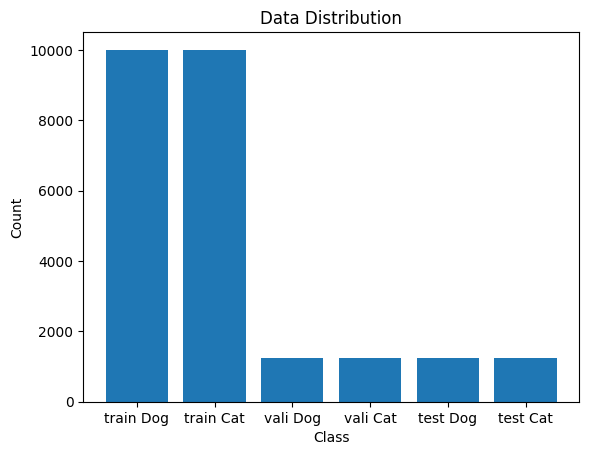

Found 20003 files belonging to 2 classes.
Found 2499 files belonging to 2 classes.
Found 2503 files belonging to 2 classes.


In [18]:
pet_train_path = '/content/drive/MyDrive/PetImages/train/'
pet_validation_path = '/content/drive/MyDrive/PetImages/validation/'
pet_test_path = '/content/drive/MyDrive/PetImages/test/'
train_dog_count = count_images(os.path.join(pet_train_path,'Dog'))
train_cat_count = count_images(os.path.join(pet_train_path,'Cat'))
validation_dog_count = count_images(os.path.join(pet_validation_path,'Dog'))
validation_cat_count = count_images(os.path.join(pet_validation_path,'Cat'))
test_dog_count = count_images(os.path.join(pet_test_path,'Dog'))
test_cat_count = count_images(os.path.join(pet_test_path,'Cat'))
data_distribution = {'train Dog': train_dog_count,
                     'train Cat': train_cat_count,
                     'vali Dog': validation_dog_count,
                     'vali Cat': validation_cat_count,
                     'test Dog': test_dog_count,
                     'test Cat': test_cat_count}
plot_data_distribution(data_distribution)

IMAGE_SIZE = (160,160) # 64 fast testing, 128 lightweight CNN, 160 MobileNetV2, 224 VGG16/ResNet
IMAGE_SIZE_pre = (256,256) # image size for test data before preprocess, to reduce blurry
BATCH_SIZE = 32
#dog_image_paths = [os.path.join(dog_data_path, fname) for fname in os.listdir(dog_data_path) if fname.endswith('.jpg')]
#dogs_train = tf.data.Dataset.from_tensor_slices(dog_image_paths)
pets_train = image_dataset_from_directory(pet_train_path,batch_size=BATCH_SIZE,image_size=IMAGE_SIZE_pre,
                                          shuffle=True,label_mode='binary',seed=1,color_mode='rgb')
pets_validation = image_dataset_from_directory(pet_validation_path,batch_size=BATCH_SIZE,image_size=IMAGE_SIZE,
                                               shuffle=True,label_mode='binary',seed=1,color_mode='rgb')
pets_test = image_dataset_from_directory(pet_test_path,batch_size=BATCH_SIZE,image_size=IMAGE_SIZE,
                                         shuffle=False,label_mode='binary',color_mode='rgb')
# handles RGB conversion automatically, Keeping the validation and testdata
# in the same order ensures deterministic and comparable evaluations across epochs

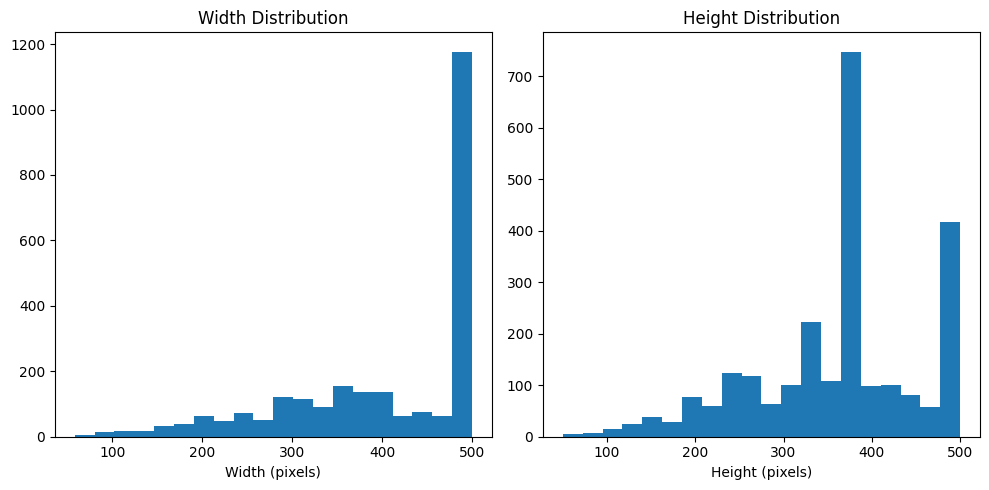

In [ ]:
# plot resolution distribution
resolutions = image_resolution(pet_validation_path)
widths, heights = zip(*resolutions) # upzip
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.hist(widths, bins=20)
plt.title("Width Distribution")
plt.xlabel("Width (pixels)")
plt.subplot(1, 2, 2)
plt.hist(heights, bins=20)
plt.title("Height Distribution")
plt.xlabel("Height (pixels)")
plt.tight_layout()
plt.show()

In [19]:
# Preprocessing
# 1. Data augmentation layer
augmentation_layer = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.05,fill_mode='reflect'),
    tf.keras.layers.RandomZoom(height_factor=(-0.2,0.2), width_factor=(-0.2,0.2),fill_mode='reflect'),
    tf.keras.layers.RandomShear(0.1,fill_mode='reflect'),
    tf.keras.layers.RandomTranslation(0.1,0.2,fill_mode='reflect'),
    tf.keras.layers.RandomContrast(0.1),
    tf.keras.layers.RandomBrightness(0.2) # value_range=[]
])
# 1.1 Cat augmentation layer
cat_augmentation_layer = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.1,fill_mode='reflect'),
])
# 2. Normalization, covert pixel values from [0,255] to [0,1]. Leave label y unchanged.
normalization_layer = tf.keras.layers.Rescaling(1./255)
# apply preprocessing
pets_train = pets_train.map(lambda x,y: (augment_image(augmentation_layer,x),y),
                            num_parallel_calls=tf.data.AUTOTUNE)
#pets_train = pets_train.map(lambda x,y: (augment_cats_batch(x,y,cat_augmentation_layer)))

pets_train = pets_train.map(lambda x,y: (preprocess_image(normalization_layer,x,IMAGE_SIZE),y))
# only normalize validation and test sets
pets_validation = pets_validation.map(lambda x,y: (normalization_layer(x),y))
pets_test = pets_test.map(lambda x,y: (normalization_layer(x),y))
print("Finished Normalization \n")
# 3. Force 3 channels
pets_train = pets_train.map(force_rgb)
pets_validation = pets_validation.map(force_rgb)
pets_test = pets_test.map(force_rgb)
#pets_combine = pets_validation.concatenate(pets_test)
# 4. Performance optimization, Caching and Prefetching
AUTOTUNE = tf.data.AUTOTUNE
pets_train = pets_train.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
pets_validation = pets_validation.cache().prefetch(tf.data.AUTOTUNE)
pets_test = pets_test.cache().prefetch(tf.data.AUTOTUNE)

Finished Normalization 



In [22]:
for images, labels in pets_train.take(9):
    print(f"Number of images: {images.shape[0]}")
    print(f"Number of labels: {labels.shape[0]}")
    plt.figure(figsize=(12, 12))
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(np.clip(images[i,:,:].numpy(), 0, 1))
        plt.title(f"Label: {labels[i].numpy()}")
        plt.axis("off")
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [23]:
# plot validation images
for images, labels in pets_validation.take(9):
  plt.figure(figsize=(12,12))
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(np.clip(images[i,:,:].numpy(), 0, 1))
    plt.title(f"Label: {labels[i].numpy()}")
    plt.axis("off")
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# Model Construction, iteration 3
model = tf.keras.Sequential([
    # input layer
    tf.keras.layers.Input(shape=IMAGE_SIZE+(3,)),
    # First Conv block
    tf.keras.layers.Conv2D(32,kernel_size=(3,3),padding='same',strides=1,kernel_initializer='he_normal'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.Conv2D(32,kernel_size=(3,3),padding='same',strides=1,kernel_initializer='he_normal'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D(pool_size=(2,2)),
    # Second Conv block
    tf.keras.layers.Conv2D(64,kernel_size=(3,3),padding='same',strides=1,kernel_initializer='he_normal'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.Conv2D(64,kernel_size=(3,3),padding='same',strides=1,kernel_initializer='he_normal'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D(pool_size=(2,2)),
    # Third Conv block
    tf.keras.layers.Conv2D(128,kernel_size=(3,3),padding='same',strides=1,kernel_initializer='he_normal'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.Conv2D(128,kernel_size=(3,3),padding='same',strides=1,kernel_initializer='he_normal'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D(pool_size=(2,2)),
    #Flattern/GlobalAveragePooling2D
    tf.keras.layers.Flatten(),
    #tf.keras.layers.GlobalAveragePooling2D(),
    # Dense layers
    #tf.keras.layers.Dense(256,activation='relu',kernel_regularizer=tf.keras.regularizers.L2(1e-3)),
    tf.keras.layers.Dense(256,activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.5),
    # Output layer, binary classification
    tf.keras.layers.Dense(1,activation='sigmoid')
])
# apply learning rate decay
learning_rate_decay = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate = 1e-3,
    decay_steps = 20000//BATCH_SIZE*5, # num_image//batchSize (steps per epoch) * n (decay every n epoch)
    decay_rate = 0.8
)

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate_decay),
              loss='binary_crossentropy',metrics=['accuracy'])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 256, 256, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 256, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_12 (ReLU)                 │ (None, 256, 256, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 256, 256, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 256, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_13 (ReLU)                 │ (None, 256, 256, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_14 (ReLU)                 │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 128, 128, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_15 (ReLU)                 │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_16 (ReLU)                 │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 64, 64, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_17 (ReLU)                 │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 131072)         │             

 Total params: 33,844,769 (129.11 MB)

 Trainable params: 33,843,361 (129.10 MB)

 Non-trainable params: 1,408 (5.50 KB)

In [20]:
# Model Construction, iteration 4
n_channel = 32
dropout_rate = 0.2
L2_regularizer = 1e-4
model = tf.keras.Sequential([
    # input layer
    tf.keras.layers.Input(shape=IMAGE_SIZE+(3,)),
    # First Conv block
    tf.keras.layers.Conv2D(n_channel,kernel_size=(3,3),padding='same',strides=1,kernel_initializer='he_normal',
                           kernel_regularizer=tf.keras.regularizers.L2(L2_regularizer)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D(pool_size=(2,2)),
    tf.keras.layers.Dropout(dropout_rate),
    # Second Conv block
    tf.keras.layers.Conv2D(2*n_channel,kernel_size=(3,3),padding='same',strides=1,kernel_initializer='he_normal',
                           kernel_regularizer=tf.keras.regularizers.L2(L2_regularizer)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D(pool_size=(2,2)),
    tf.keras.layers.Dropout(dropout_rate),
    # Third Conv block
    tf.keras.layers.Conv2D(4*n_channel,kernel_size=(3,3),padding='same',strides=1,kernel_initializer='he_normal',
                           kernel_regularizer=tf.keras.regularizers.L2(L2_regularizer)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D(pool_size=(2,2)),
    tf.keras.layers.Dropout(dropout_rate),
    # Forth Conv block
    tf.keras.layers.Conv2D(8*n_channel,kernel_size=(3,3),padding='same',strides=1,kernel_initializer='he_normal',
                           kernel_regularizer=tf.keras.regularizers.L2(L2_regularizer)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D(pool_size=(2,2)),
    tf.keras.layers.Dropout(dropout_rate),
    # Fifth Conv block
    tf.keras.layers.Conv2D(16*n_channel,kernel_size=(3,3),padding='same',strides=1,kernel_initializer='he_normal',
                           kernel_regularizer=tf.keras.regularizers.L2(L2_regularizer)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D(pool_size=(2,2)),
    tf.keras.layers.Dropout(dropout_rate),
    # Dense layers
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(512,activation='relu',kernel_regularizer=tf.keras.regularizers.L2(5e-3)),
    #tf.keras.layers.Dense(512,activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(dropout_rate),
    # Output layer, binary classification
    tf.keras.layers.Dense(1,activation='sigmoid')
])

model.compile(optimizer=tf.keras.optimizers.Adam(),
              loss='binary_crossentropy',metrics=['accuracy'])
model.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_15 (ReLU)                 │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_16 (ReLU)                 │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_17 (ReLU)                 │ (None, 40, 40, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 20, 20, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 20, 20, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_18 (ReLU)                 │ (None, 20, 20, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 10, 10, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 10, 10, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 8,129,217 (31.01 MB)

 Trainable params: 8,126,209 (31.00 MB)

 Non-trainable params: 3,008 (11.75 KB)

In [21]:
# apply early stopping
learning_rate_decay = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    patience=2,
    factor=0.5,
    min_lr=1e-6,
    verbose=1
)
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True)
history = model.fit(pets_train, validation_data=pets_validation, epochs=30, callbacks=[learning_rate_decay,early_stop])

Epoch 1/30
626/626 ━━━━━━━━━━━━━━━━━━━━ 221s 58ms/step - accuracy: 0.5941 - loss: 2.6418 - val_accuracy: 0.6783 - val_loss: 0.9217 - learning_rate: 0.0010
Epoch 2/30
626/626 ━━━━━━━━━━━━━━━━━━━━ 26s 42ms/step - accuracy: 0.6702 - loss: 0.9194 - val_accuracy: 0.7291 - val_loss: 0.8001 - learning_rate: 0.0010
Epoch 3/30
626/626 ━━━━━━━━━━━━━━━━━━━━ 26s 42ms/step - accuracy: 0.7396 - loss: 0.7976 - val_accuracy: 0.7075 - val_loss: 0.7927 - learning_rate: 0.0010
Epoch 4/30
626/626 ━━━━━━━━━━━━━━━━━━━━ 26s 42ms/step - accuracy: 0.7754 - loss: 0.7399 - val_accuracy: 0.8083 - val_loss: 0.6825 - learning_rate: 0.0010
Epoch 5/30
626/626 ━━━━━━━━━━━━━━━━━━━━ 26s 42ms/step - accuracy: 0.8092 - loss: 0.6600 - val_accuracy: 0.8299 - val_loss: 0.5858 - learning_rate: 0.0010
Epoch 6/30
626/626 ━━━━━━━━━━━━━━━━━━━━ 26s 42ms/step - accuracy: 0.8372 - loss: 0.6012 - val_accuracy: 0.8611 - val_loss: 0.5764 - learning_rate: 0.0010
Epoch 7/30
626/626 ━━━━━━━━━━━━━━━━━━━━ 26s 42ms/step - accuracy: 0.8503 - 

In [ ]:
model.save('/content/drive/MyDrive/PetImages/Cat_Dog_model.keras')

In [7]:
model = tf.keras.models.load_model('/content/drive/MyDrive/PetImages/Cat_Dog_best_model.keras')
model.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_45 (Conv2D)              │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_54          │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_45 (ReLU)                 │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_45 (MaxPooling2D) │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_54 (Dropout)            │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_46 (Conv2D)              │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_55          │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_46 (ReLU)                 │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_46 (MaxPooling2D) │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_55 (Dropout)            │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_47 (Conv2D)              │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_56          │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_47 (ReLU)                 │ (None, 40, 40, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_47 (MaxPooling2D) │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_56 (Dropout)            │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_48 (Conv2D)              │ (None, 20, 20, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_57          │ (None, 20, 20, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_48 (ReLU)                 │ (None, 20, 20, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_48 (MaxPooling2D) │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_57 (Dropout)            │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_49 (Conv2D)              │ (None, 10, 10, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_58          │ (None, 10, 10, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 24,381,637 (93.01 MB)

 Trainable params: 8,126,209 (31.00 MB)

 Non-trainable params: 3,008 (11.75 KB)

 Optimizer params: 16,252,420 (62.00 MB)

In [16]:
model.layers[-10].get_config()


{'name': 'conv2d_49',
 'trainable': True,
 'dtype': {'module': 'keras',
  'class_name': 'DTypePolicy',
  'config': {'name': 'float32'},
  'registered_name': None},
 'filters': 512,
 'kernel_size': (3, 3),
 'strides': (1, 1),
 'padding': 'same',
 'data_format': 'channels_last',
 'dilation_rate': (1, 1),
 'groups': 1,
 'activation': 'linear',
 'use_bias': True,
 'kernel_initializer': {'module': 'keras.initializers',
  'class_name': 'HeNormal',
  'config': {'seed': None},
  'registered_name': None},
 'bias_initializer': {'module': 'keras.initializers',
  'class_name': 'Zeros',
  'config': {},
  'registered_name': None},
 'kernel_regularizer': {'module': 'keras.regularizers',
  'class_name': 'L2',
  'config': {'l2': 0.0001},
  'registered_name': None},
 'bias_regularizer': None,
 'activity_regularizer': None,
 'kernel_constraint': None,
 'bias_constraint': None}

iteration 1:
1. Start with simple CNN(36,64,128,flatten,dense256), image size = (160,160)
2. Apply data augmentation (horizontal flip, rotation, zoom, brightness, contrast, translation)
3. Apply dropout at dense layer
4. Adjust Dropout rate and learning rate
Results: Training accuracy plateaus around 75-80%, with validation accuracy flautuate after ~5 epoch; high bias and high variance)

iteration 2:
1. Clean up the data, manually check for mislabelled and corrupted images. (Always check your data first!).
2. Add kernel_initializer='he_normal’, BatchNormalization after each Conv layer
3. Apply learning rate decay and early stopping
4. Try normalization at Conv layer, adjust dropout rate and GlobalAveragePooling to control overfitting
Results: Training accuracy plateaus between 85-90% depends on how much regularization; validation accuracy plateaus around 75%; still high bias and high variance)

iteration 3:
1. Set one goal at a time; First try to increase the training accuracy. (a) skip the data augmentation (don't start with data augmentation and add one at a time) (b) add more conv layers, stack 2 conv layer at each block to extract larger features (two 3x3 instead of one 5x5 reduces the number of parameters), padding='same', strides=1. Allow a higher patience = 5 for the early stopping. Learning rate = 1e-3 with decay ratio=0.8 every 5 epochs (usually validation loss stops decreasing after 5 epochs). (c) Increase image size to (256,256)
2. Remove regularization at Conv layers and set dropout rate to 0.5.
Results: Training accuracy reaches 99.2%; validation accuracy fluctuates between 80-85%, Validation Metrics:
Precision: 0.9043, Recall: 0.8101, F1-Score: 0.8546. Confusion matrix higher false positive (cats labeled as dogs)

iteration 4:
1. Set the goal to address overfitting, try different methods and apply one at a time. (a) increase dropout rate to 0.8. Validation accuracy reaches ~85% and fluctuates. (b) Apply dropout layer after each MaxPooling layer. (c) Apply L2 regularization to the fully connected layer. (d) Change the number of convolution layers.

2. Data distortion introduced should be representation of the type of noise/distortion in the test/validationi set. Introduce one augmentation method at a time and set the values based on the structure of the dataset and its effect on model performance.

After


In [26]:
# Evaluate on validation set
# train_loss, train_accuracy = model.evaluate(pets_train)
val_loss, val_accuracy = model.evaluate(pets_validation)
print(f"Validation Loss: {val_loss}, Validation Accuracy: {val_accuracy}")
# get prediction
threshold = 0.5
y_predict = (model.predict(pets_validation) > threshold).astype(int)
y_true = np.concatenate([y.numpy() for _,y in pets_validation])
# Compute metrics
print("Validation Metrics:")
print(f"Precision: {precision_score(y_true, y_predict):.4f}")
print(f"Recall: {recall_score(y_true, y_predict):.4f}")
print(f"F1-Score: {f1_score(y_true, y_predict):.4f}")

78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9447 - loss: 0.2816
Validation Loss: 0.27639833092689514, Validation Accuracy: 0.9447115659713745
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
Validation Metrics:
Precision: 0.9505
Recall: 0.9383
F1-Score: 0.9444


In [27]:
# Evaluate on test set
test_loss, test_accuracy = model.evaluate(pets_test)
print(f"Test Loss: {test_loss}, Test Accuracy: {test_accuracy}")
# get prediction
y_predict = (model.predict(pets_test) > threshold).astype(int)
y_true = np.concatenate([y.numpy() for _,y in pets_test])
# Compute metrics
print("Test Metrics:")
print(f"Precision: {precision_score(y_true, y_predict):.4f}")
print(f"Recall: {recall_score(y_true, y_predict):.4f}")
print(f"F1-Score: {f1_score(y_true, y_predict):.4f}")

79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 69ms/step - accuracy: 0.9442 - loss: 0.3024
Test Loss: 0.302439421415329, Test Accuracy: 0.9336265325546265
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step
Test Metrics:
Precision: 0.9495
Recall: 0.9161
F1-Score: 0.9325


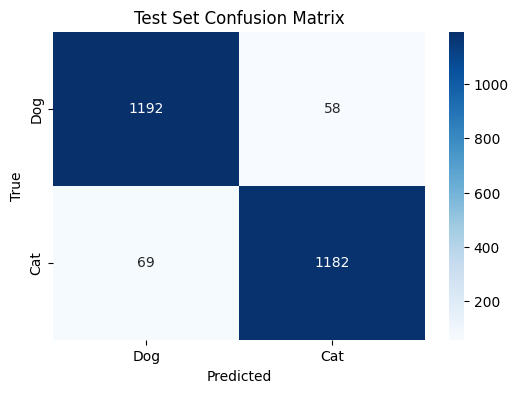

In [ ]:
# Confusion matrix
cm = confusion_matrix(y_true, y_predict)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Dog', 'Cat'], yticklabels=['Dog', 'Cat'])
plt.title('Test Set Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

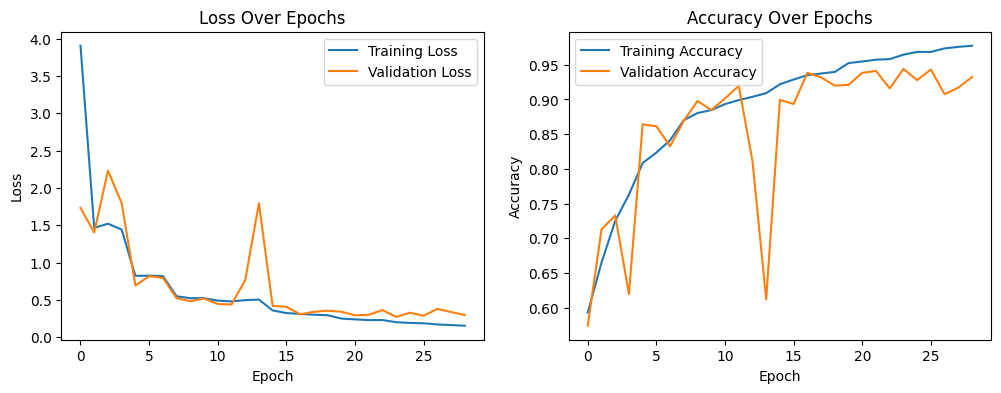

In [ ]:
# Training History
history_dict = history.history
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_dict['loss'], label='Training Loss')
plt.plot(history_dict['val_loss'], label='Validation Loss')
plt.title('Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history_dict['accuracy'], label='Training Accuracy')
plt.plot(history_dict['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

Dog Recall: 0.9536
Cat Recall: 0.9448
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 621ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━

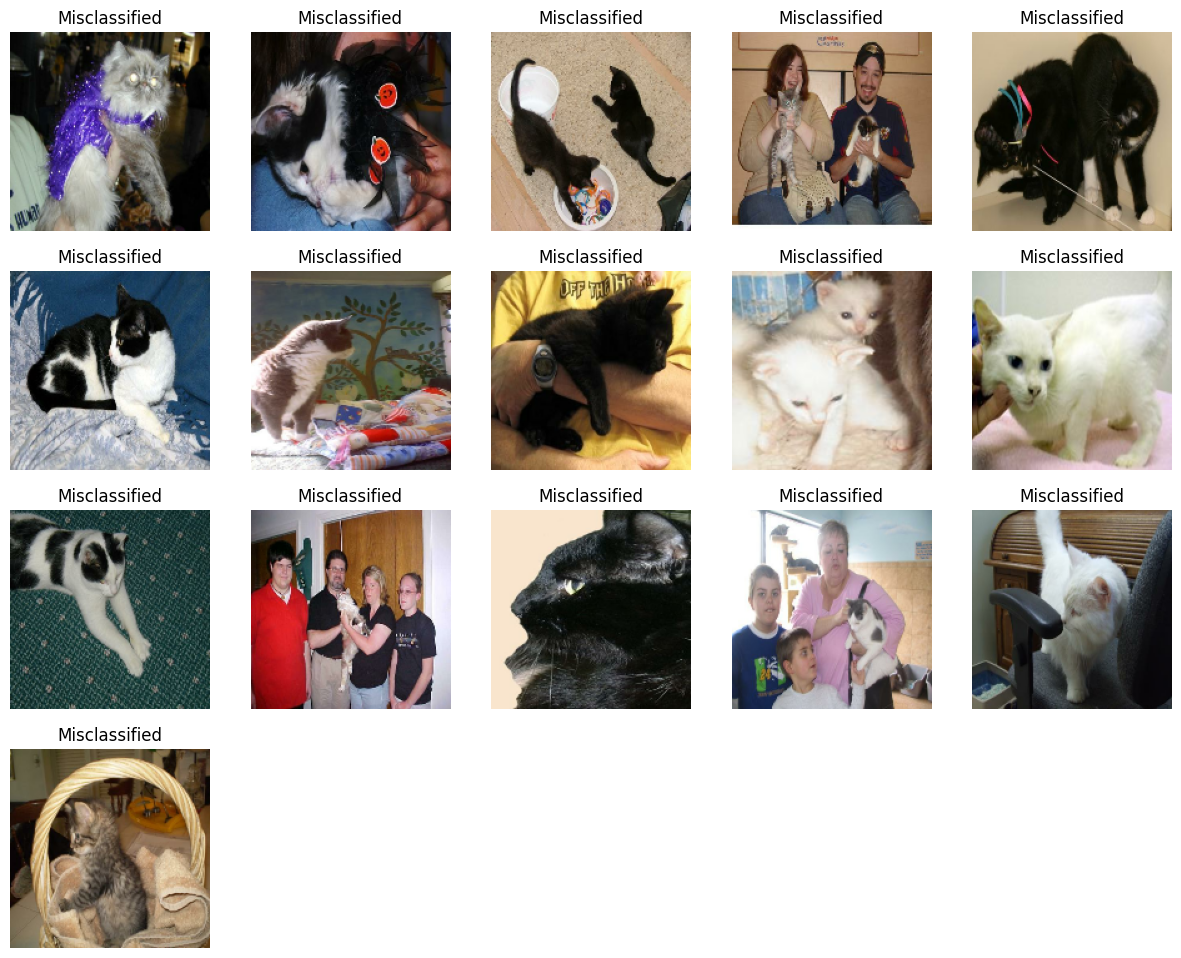

In [ ]:
# Class-specific recall
dog_recall = cm[0, 0] / (cm[0, 0] + cm[0, 1])  # Dogs correctly classified / Total dogs
cat_recall = cm[1, 1] / (cm[1, 0] + cm[1, 1])  # Cats correctly classified / Total cats
print(f"Dog Recall: {dog_recall:.4f}")
print(f"Cat Recall: {cat_recall:.4f}")

# Visualize misclassified cats
misclassified = []
for images, labels in pets_test:
    preds = (model.predict(images) > 0.5).astype(int)
    for i in range(len(labels)):
        if labels[i].numpy() == 0 and preds[i] == 1:  # True cat, predicted dog
            misclassified.append(images[i].numpy())
        elif labels[i].numpy() == 1 and preds[i] == 0:  # True dog, predicted cat
            misclassified.append(images[i].numpy())
        if len(misclassified) >= 25:
            break
plt.figure(figsize=(15, 15))
for i in range(min(25, len(misclassified))):
    plt.subplot(5, 5, i+1)
    plt.imshow(misclassified[i])
    plt.title("Misclassified")
    plt.axis('off')
plt.show()